## Evaluation on Evenly Spaced Wind Tasks

The cluster assignments of 20 evenly spaced wind tasks between -5 and +5 are analyzed to identify the relationship between wind magnitude and K-Means clusters.

In [36]:
import numpy as np
import matplotlib.pyplot as plt
import os
import sys

sys.path.insert(0, os.path.abspath("../../.."))
sys.path.insert(0, os.path.abspath("../.."))

from cartpole_wind import sample_tasks_eval

# Recreate the original 20 evenly spaced winds
env_configs = sample_tasks_eval(num_envs=20)

# Load the original K Means cluster assignments
cluster_labels = np.load(
    "../../../checkpoints/cartpole_wind_cluster_labels.npy"
)

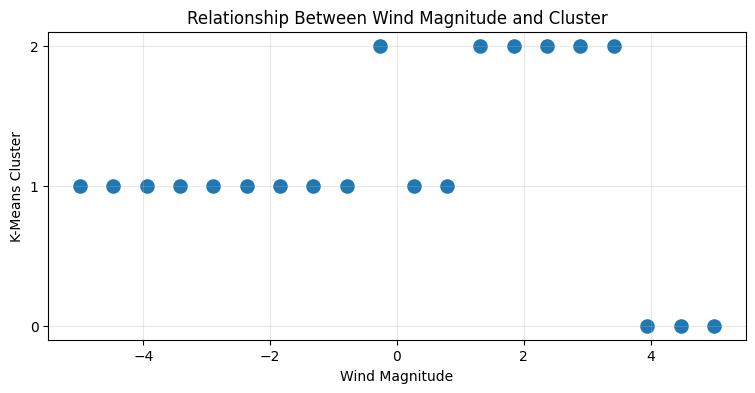

In [37]:
# Extract wind magnitudes and their cluster assignments
wind_values = np.array([cfg["wind_mag"] for cfg in env_configs])

plt.figure(figsize=(9, 4))
plt.scatter(wind_values, cluster_labels, s=90)

plt.xlabel("Wind Magnitude")
plt.ylabel("K-Means Cluster")
plt.yticks([0, 1, 2])
plt.title("Relationship Between Wind Magnitude and Cluster")
plt.grid(alpha=0.3)
plt.show()

## Evaluation on Random Wind Tasks

The cluster assignments of 20 randomly sampled wind tasks are compared with those from the original experiment using the same K  Means model.

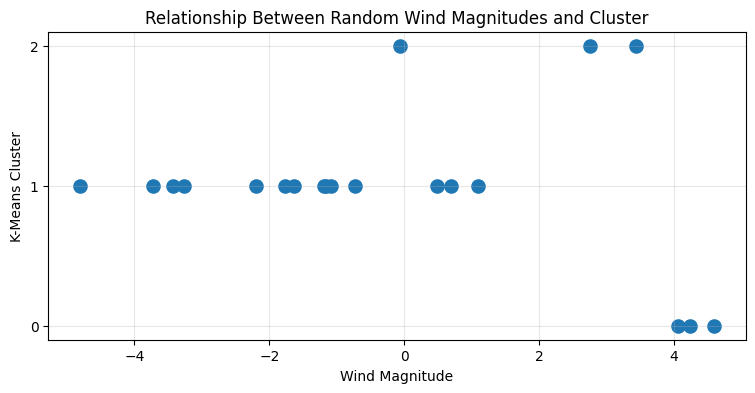

In [38]:
# Load the results from the random wind experiment.
random_results = np.load("../../../checkpoints/cartpole_wind_random_results.npz")

random_wind_values = random_results["wind_values"]
random_cluster_labels = random_results["cluster_labels"]

# Plot the relationship between random wind magnitudes and clusters.
plt.figure(figsize=(9, 4))
plt.scatter(random_wind_values, random_cluster_labels, s=90)

plt.xlabel("Wind Magnitude")
plt.ylabel("K-Means Cluster")
plt.yticks([0, 1, 2])
plt.title("Relationship Between Random Wind Magnitudes and Cluster")
plt.grid(alpha=0.3)
plt.show()

## Wind Magnitude Prediction Using K-Means Clusters

The mean wind magnitude of each cluster is calculated using the original evenly spaced wind tasks. These values are then used to predict the wind magnitudes of the random tasks. The prediction error is evaluated using Mean Absolute Error (MAE).

In [39]:
# Calculate the mean wind for each original cluster
cluster_wind_means = {}

for cluster in np.unique(cluster_labels):
    mean_wind = np.mean(wind_values[cluster_labels == cluster])
    cluster_wind_means[cluster] = mean_wind

    print(f"Cluster {cluster}: Mean Wind = {mean_wind:.2f}")

Cluster 0: Mean Wind = 4.47
Cluster 1: Mean Wind = -2.27
Cluster 2: Mean Wind = 1.93


In [40]:
# Predict wind using the original cluster means
predicted_wind = np.array([
    cluster_wind_means[cluster]
    for cluster in random_cluster_labels
])

# Compare actual and predicted wind
for actual, predicted in zip(random_wind_values, predicted_wind):
    print(f"Actual Wind = {actual:.2f} | Predicted Wind = {predicted:.2f}")

# Calculate the Mean Absolute Error.
mae = np.mean(np.abs(random_wind_values - predicted_wind))

print(f"\nMean Absolute Error: {mae:.2f}")

Actual Wind = -3.43 | Predicted Wind = -2.27
Actual Wind = 3.44 | Predicted Wind = 1.93
Actual Wind = -4.81 | Predicted Wind = -2.27
Actual Wind = 4.24 | Predicted Wind = 4.47
Actual Wind = -3.72 | Predicted Wind = -2.27
Actual Wind = 4.07 | Predicted Wind = 4.47
Actual Wind = -0.73 | Predicted Wind = -2.27
Actual Wind = 0.49 | Predicted Wind = -2.27
Actual Wind = -1.19 | Predicted Wind = -2.27
Actual Wind = 2.76 | Predicted Wind = 1.93
Actual Wind = -2.20 | Predicted Wind = -2.27
Actual Wind = 4.59 | Predicted Wind = 4.47
Actual Wind = 1.09 | Predicted Wind = -2.27
Actual Wind = -0.06 | Predicted Wind = 1.93
Actual Wind = 0.70 | Predicted Wind = -2.27
Actual Wind = -1.77 | Predicted Wind = -2.27
Actual Wind = -1.08 | Predicted Wind = -2.27
Actual Wind = -3.26 | Predicted Wind = -2.27
Actual Wind = -1.63 | Predicted Wind = -2.27
Actual Wind = -1.16 | Predicted Wind = -2.27

Mean Absolute Error: 1.32


In [41]:
# Use the mean wind of the original tasks as a baseline prediction.
baseline_prediction = np.mean(wind_values)

# Calculate the baseline prediction error on random tasks.
baseline_mae = np.mean(
    np.abs(random_wind_values - baseline_prediction)
)

print(f"K-Means MAE: {mae:.2f}")
print(f"Baseline MAE: {baseline_mae:.2f}")

K-Means MAE: 1.32
Baseline MAE: 2.32
